![Banner](./img/AI_Special_Program_Banner.jpg)



# Exercises for Classification
---

**Assignment 5 &mdash; Soyeon Park**

In this exercise, you are to *apply* the classification algorithms that you have now become familiar with. Specifically, you should try out which algorithm performs *best* on a data set about heart disease: a **decision tree**, a **logistic regression**, the **K-Nearest-Neighbor algorithm** or **Random Forest**.

## Data
---

Here we look at the [Heart Disease Data Set](https://archive.ics.uci.edu/ml/datasets/heart+disease). This contains patient data from a hospital in Cleveland.  
The "target" field refers to the presence of heart disease in the patient. It is the attribute `num`, integer valued, 0 means no disease and 1 to 4 for disease.  
Here are the relevant attributes:

### Attributes

* **age**: age in years
* **sex**: sex
* **cp**: chest pain type
        -- Value 1: typical angina
        -- Value 2: atypical angina
        -- Value 3: non-anginal pain
        -- Value 4: asymptomatic
* **trestbps**: resting blood pressure (in mm Hg on admission to the hospital)
* **chol**: serum cholestoral in mg/dl
* **fbs**: (fasting blood sugar > 120 mg/dl) (true; false)
* **restecg**: resting electrocardiographic results
        -- Value 0: normal
        -- Value 1: having ST-T wave abnormality (T wave inversions and/or ST
                    elevation or depression of > 0.05 mV)
        -- Value 2: showing probable or definite left ventricular hypertrophy
                    by Estes' criteria
* **thalach**: maximum heart rate achieved
* **exang**: exercise induced angina (yes; no)
* **oldpeak:** ST depression induced by exercise relative to rest
* **slope:** the slope of the peak exercise ST segment
        -- Value 1: upsloping
        -- Value 2: flat
        -- Value 3: downsloping
* **ca:** number of major vessels (0-3) colored by flourosopy
* **thal:** normal; fixed defect; reversable defect
* **num:** 0 (no presence) to 4

For our classification model, a precise understanding of the individual attributes and their meaning is not important in the context of this exercise. However, in reality, data science and machine learning are **interdisciplinary** fields, so the validity of the data should be clarified as well as the resulting ML models.

Further information on the data can be found in `data/heart-disease.names`.

### Reading in the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_raw = pd.read_csv('./data/heart_desease.csv')

In [3]:
df_raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,male,typical angina,145.0,233.0,True,ventricual hypertrophy,150.0,yes,2.3,downsloping,0,fixed defect,0
1,67.0,male,asymptomatic,160.0,286.0,False,ventricual hypertrophy,108.0,no,1.5,flat,3,normal,2
2,67.0,male,asymptomatic,120.0,229.0,False,ventricual hypertrophy,129.0,no,2.6,flat,2,reversable defect,1
3,37.0,male,non-anginal pain,130.0,250.0,False,normal,187.0,yes,3.5,downsloping,0,normal,0
4,41.0,female,atypical angina,130.0,204.0,False,ventricual hypertrophy,172.0,yes,1.4,upsloping,0,normal,0


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    object 
 2   cp        303 non-null    object 
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    bool   
 6   restecg   303 non-null    object 
 7   thalach   303 non-null    float64
 8   exang     303 non-null    object 
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    object 
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  num       303 non-null    int64  
dtypes: bool(1), float64(5), int64(1), object(7)
memory usage: 31.2+ KB


We note: our data set contains both **numerical** and **categorical** features!

<h1 style="color:blue">Exercises</h1>

In this exercise, you are to use 4 different classification models for the available data: a **decision tree**, a **logistic regression**, the **K-Nearest-Neighbor algorithm** and **Random Forest**. Which model best represents the data at hand?

**Note:** For the sake of simplicity, you can determine the performance of the algorithms using the *entire* data. **So you *train* the model on the same data on which you then *evaluate* the model**. In the next lesson, we will explain in detail why this is not actually useful...  
We use **factorized data** to get numerical values for the categorical ones. One Hot Encoding may be better, but we will not consider this in this exercise

---

<h2 style="color:blue">Task 1 - Decision tree</h2>

Before you can train a decision tree, the data must first be prepared.

<h3 style="color:blue">Task 1.1 - Binarization of the label</h3>

The target size (*label*) that we want to predict is stored in the variable `num`. This indicates 5 stages of reduction in the diameter of vessels, which determine the presence of heart disease. No disease is present for the value $0$. Analogous to the publications on this data set, we want to consider this classification problem as a **binary decision problem**. This means that we only distinguish between normal findings ($\hat = 0$) and the presence of a disease ($1,\dots,4$).

Therefore, first carry out a binarization ($0,1$) of the target. Save the result in the variable `y`.

**Notes:**

* There are many ways to achieve this, but Panda's [apply()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html) is certainly a good option.

In [5]:
y = df_raw['num'].apply(lambda v: 1 if v > 0 else 0)
y.name = 'target'

print("Original 'num' distribution:")
print(df_raw['num'].value_counts().sort_index(), "\n")

print("Binarised target 'y' distribution:")
print(y.value_counts().sort_index(), "\n")

print(f"Share of patients with disease : {y.mean():.2%}")
print(f"Majority-class baseline        : {max(y.mean(), 1 - y.mean()):.2%}")

y.head()

Original 'num' distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64 

Binarised target 'y' distribution:
target
0    164
1    139
Name: count, dtype: int64 

Share of patients with disease : 45.87%
Majority-class baseline        : 54.13%


0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64

<h3 style="color:blue">Task 1.2 - Integer/Ordinal Encoding </h3>

In order to use the categorical variables as input for the model, they must be converted into numerical values. The easiest way to achieve this is through *Integer Encoding* (also *Ordinal Encoding*). Here, each value of a variable is simply assigned an integer value. This type of encoding is actually only appropriate if the characteristics are ordinal scaled, i.e. if there is a fixed relationship between the categories.

Perform an integer encoding for the categorical variables. Save the resulting feature matrix (containing all encoded and numeric variables) as `X_enc`.

**Notes:**

* You can perform the encoding by using pandas:
    1. Using the pandas [Categories](https://pandas.pydata.org/docs/user_guide/categorical.html)
* The label vector `y` must not be contained in the feature matrix!

**Solution:**

In [6]:
X_raw = df_raw.drop(columns=['num'])

cat_cols = X_raw.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]

print("Categorical features:", cat_cols)
print("Numerical features  :", num_cols, "\n")

X_enc = X_raw.copy()
for col in cat_cols:
    X_enc[col] = X_enc[col].astype('category').cat.codes

print("Encoding scheme:")
for col in cat_cols:
    mapping = dict(enumerate(X_raw[col].astype('category').cat.categories))
    print(f"  {col:9} {mapping}")

print("\nX_enc shape:", X_enc.shape, "(label 'num' is not contained)")
X_enc.head()

Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numerical features  : ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'] 

Encoding scheme:
  sex       {0: 'female', 1: 'male'}
  cp        {0: 'asymptomatic', 1: 'atypical angina', 2: 'non-anginal pain', 3: 'typical angina'}
  fbs       {0: False, 1: True}
  restecg   {0: 'ST-T wave abnormality', 1: 'normal', 2: 'ventricual hypertrophy'}
  exang     {0: 'no', 1: 'yes'}
  slope     {0: 'downsloping', 1: 'flat', 2: 'upsloping'}
  ca        {0: '0', 1: '1', 2: '2', 3: '3', 4: 'unknown'}
  thal      {0: 'fixed defect', 1: 'normal', 2: 'reversable defect', 3: 'unknown'}

X_enc shape: (303, 13) (label 'num' is not contained)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1,3,145.0,233.0,1,2,150.0,1,2.3,0,0,0
1,67.0,1,0,160.0,286.0,0,2,108.0,0,1.5,1,3,1
2,67.0,1,0,120.0,229.0,0,2,129.0,0,2.6,1,2,2
3,37.0,1,2,130.0,250.0,0,1,187.0,1,3.5,0,0,1
4,41.0,0,1,130.0,204.0,0,2,172.0,1,1.4,2,0,1


<h3 style="color:blue">Task 1.3 - Training the decision tree</h3>

Train a decision tree with a maximum depth of 3. Use the Gini index as a measure of impurity.

**Notes:**
* Determine the accuracy of your model
* Which features were particularly important for the classification?
* Visualize the tree

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
dt.fit(X_enc, y)

acc_dt = dt.score(X_enc, y)
print(f"Decision tree accuracy: {acc_dt:.4f}\n")

importances_dt = (pd.Series(dt.feature_importances_, index=X_enc.columns)
                    .sort_values(ascending=False))

print("Feature importances (only the features the tree actually used):")
print(importances_dt[importances_dt > 0].round(4))

Decision tree accuracy: 0.8449

Feature importances (only the features the tree actually used):
cp          0.4914
ca          0.1781
thal        0.1349
age         0.0747
sex         0.0659
oldpeak     0.0402
trestbps    0.0148
dtype: float64


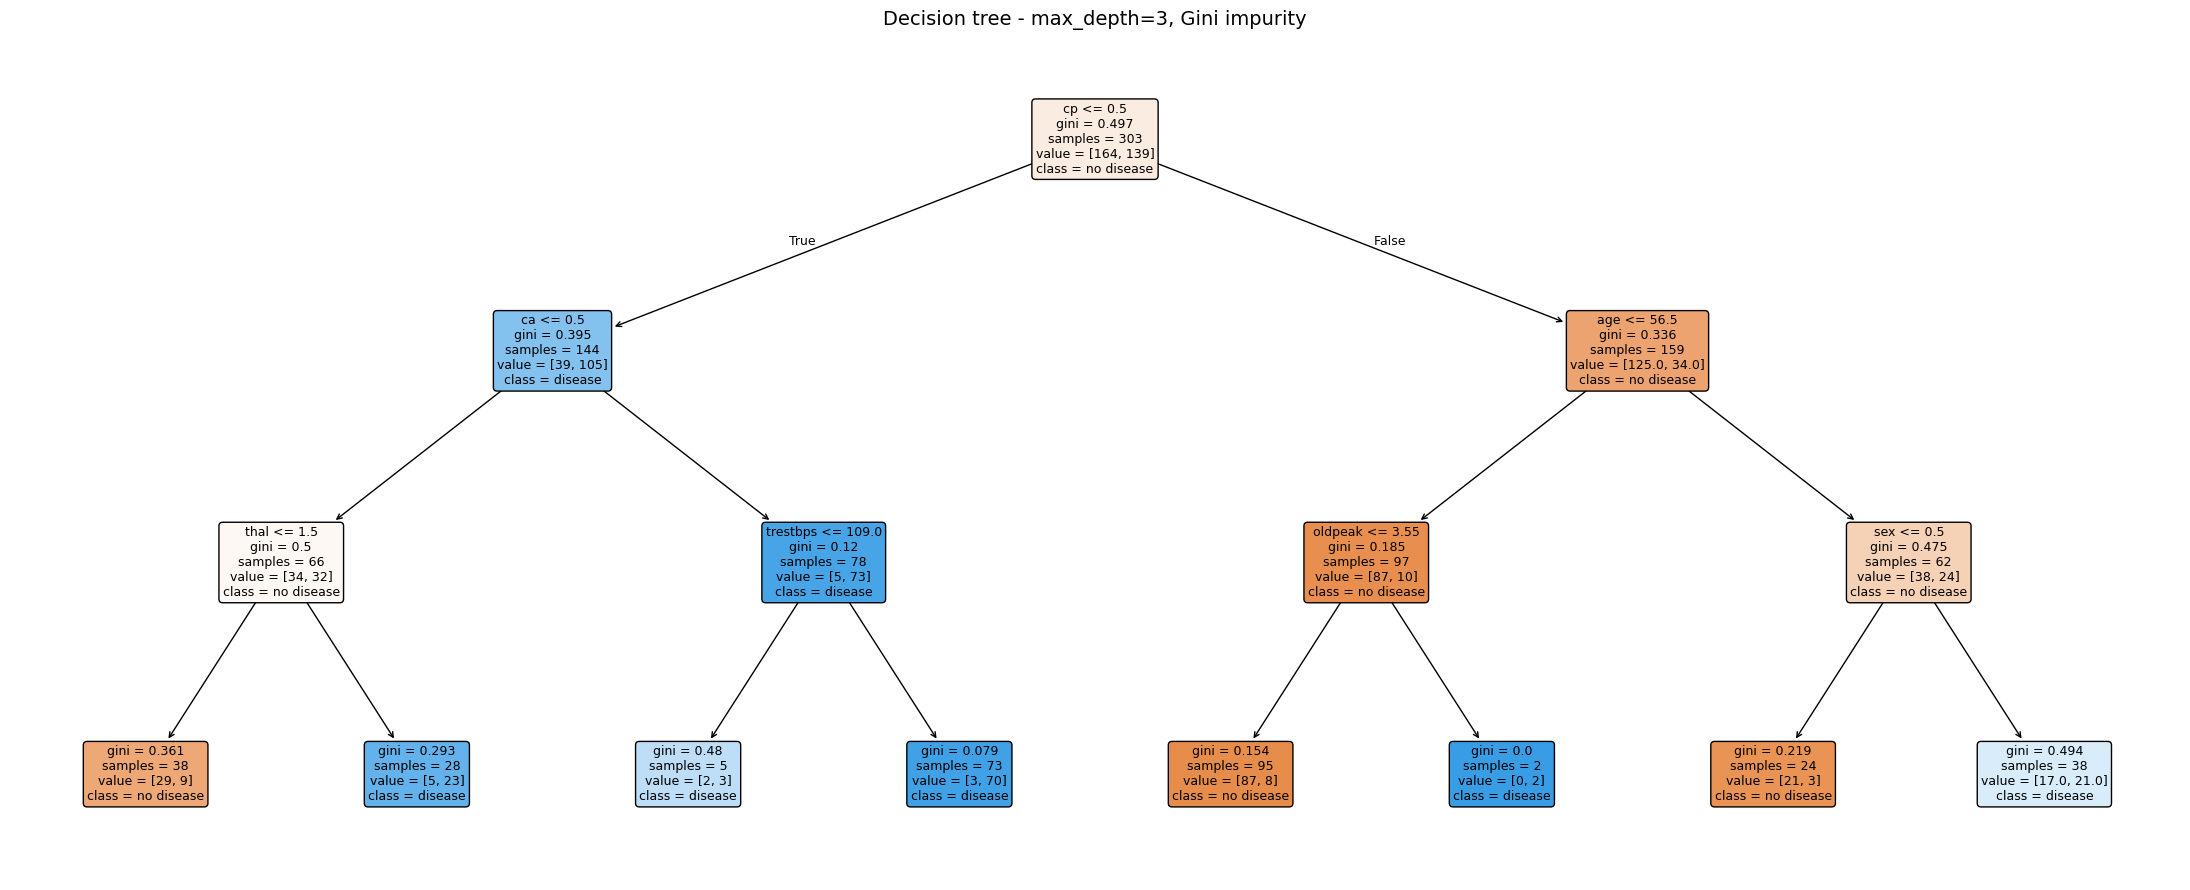

In [8]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt,
          feature_names=X_enc.columns.tolist(),
          class_names=['no disease', 'disease'],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Decision tree - max_depth=3, Gini impurity', fontsize=14)
plt.tight_layout()
plt.show()

<h2 style="color:blue">Task 2 - Logistic regression</h2>

With logistic regression, too, the data must first be prepared.

<h3 style="color:blue">Task 2.1 - Scaling the data</h3>

A major advantage of decision trees is the ability to work directly with the unscaled raw data. Logistic regression is also insensitive to unscaled data. However, since it makes sense to **regularize** the logistic regression (and this is also the default in `scikit-learn`), the data should be scaled accordingly. Suggestions as to why this is the case can be found [here](https://stats.stackexchange.com/questions/48360/is-standardization-needed-before-fitting-logistic-regression) and [here](https://stats.stackexchange.com/questions/290958/logistic-regression-and-scaling-of-features). A brief, general explanation of feature scaling is also available from [Raschka](https://sebastianraschka.com/faq/docs/when-to-standardize.html).

Scale the data (**both integer encoded and OHE**) using the [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) from `scikit-learn`. Save your feature matrix in `X_enc_std` and `X_ohe_std`.

**Notes:**
* Whether the binary categorical variables really need to be scaled is at least questionable. For the sake of simplicity, you can simply scale them as well. More information can be found [here](https://stats.stackexchange.com/questions/359015/ridge-lasso-standardization-of-dummy-indicators).

In [9]:
from sklearn.preprocessing import StandardScaler

X_ohe = pd.get_dummies(X_raw, columns=cat_cols, drop_first=False)

print("X_enc shape (integer encoded):", X_enc.shape)
print("X_ohe shape (one-hot encoded):", X_ohe.shape, "\n")

X_enc_std = pd.DataFrame(StandardScaler().fit_transform(X_enc),
                         columns=X_enc.columns)
X_ohe_std = pd.DataFrame(StandardScaler().fit_transform(X_ohe),
                         columns=X_ohe.columns)

print(f"X_enc_std -> max |mean| = {X_enc_std.mean().abs().max():.2e}, "
      f"mean std = {X_enc_std.std(ddof=0).mean():.4f}")
print(f"X_ohe_std -> max |mean| = {X_ohe_std.mean().abs().max():.2e}, "
      f"mean std = {X_ohe_std.std(ddof=0).mean():.4f}")

X_enc_std.head()

X_enc shape (integer encoded): (303, 13)
X_ohe shape (one-hot encoded): (303, 30) 

X_enc_std -> max |mean| = 4.43e-16, mean std = 1.0000
X_ohe_std -> max |mean| = 4.43e-16, mean std = 1.0000


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.948726,0.686202,1.979976,0.757525,-0.264900,2.394438,0.999230,0.017197,0.696631,1.087338,-2.274579,-0.713129,-2.244499
1,1.392002,0.686202,-0.932319,1.611220,0.760415,-0.417635,0.999230,-1.821905,-1.435481,0.397182,-0.649113,2.274127,-0.569417
2,1.392002,0.686202,-0.932319,-0.665300,-0.342283,-0.417635,0.999230,-0.902354,-1.435481,1.346147,-0.649113,1.278375,1.105664
3,-1.932564,0.686202,1.009211,-0.096170,0.063974,-0.417635,-0.904963,1.637359,0.696631,2.122573,-2.274579,-0.713129,-0.569417
4,-1.489288,-1.457296,0.038446,-0.096170,-0.825922,-0.417635,0.999230,0.980537,0.696631,0.310912,0.976352,-0.713129,-0.569417


<h3 style="color:blue">Task 2.2 - Logistic regression</h3>

Perform a logistic regression. Test your model with both the scaled integer encoded data and the scaled OHE data.

**Notes:**
* Feel free to try out several (hyper)parameters for the logistic regression. For some configurations, the solution may not converge (or not in the given number of iterations).

In [10]:
from sklearn.linear_model import LogisticRegression

lr_enc = LogisticRegression(max_iter=1000, random_state=42).fit(X_enc_std, y)
lr_ohe = LogisticRegression(max_iter=1000, random_state=42).fit(X_ohe_std, y)

acc_lr_enc = lr_enc.score(X_enc_std, y)
acc_lr_ohe = lr_ohe.score(X_ohe_std, y)

print(f"Logistic regression, integer encoded + scaled : {acc_lr_enc:.4f}")
print(f"Logistic regression, one-hot encoded + scaled : {acc_lr_ohe:.4f}")

Logistic regression, integer encoded + scaled : 0.8515
Logistic regression, one-hot encoded + scaled : 0.8713


In [11]:
rows = []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    a_enc = LogisticRegression(C=C, max_iter=5000, random_state=42).fit(X_enc_std, y).score(X_enc_std, y)
    a_ohe = LogisticRegression(C=C, max_iter=5000, random_state=42).fit(X_ohe_std, y).score(X_ohe_std, y)
    rows.append({'C': C, 'accuracy (integer enc.)': a_enc, 'accuracy (one-hot)': a_ohe})

pd.DataFrame(rows).round(4)

,C,accuracy (integer enc.),accuracy (one-hot)
0,0.01,0.8416,0.8647
1,0.10,0.8449,0.8713
2,1.00,0.8515,0.8713
3,10.00,0.8548,0.8713
4,100.00,0.8548,0.8746


<h2 style="color:blue">Task 3 - K-Nearest-Neighbors</h2>

KNN uses distances to determine the nearest neighbors. However, since we find categorical variables without a fixed order in our data, the calculation of a distance measure is questionable (see analogous exercise on clustering). We therefore have to use separate distance and similarity measures again.

Apply a KNN model with $k=5$ based on the Gower distance. Determine the accuracy.

**Notes:**
* The Gower distance is suitable here not only because of the categorical variables, but also because of the normalization ($[0,1]$) of the distance values.  
  For using gower you need to install the package with `pip install gower`
* [Gower](https://pypi.org/project/gower/) can be applied directly to the raw data
* What accuracy does the KNN model approach for particularly large $k$?

In [12]:
import gower
from sklearn.neighbors import KNeighborsClassifier

D_gower = gower.gower_matrix(X_raw)

print("Gower distance matrix:", D_gower.shape,
      f"| values range from {D_gower.min():.3f} to {D_gower.max():.3f}\n")

knn = KNeighborsClassifier(n_neighbors=5, metric='precomputed')
knn.fit(D_gower, y)

acc_knn = knn.score(D_gower, y)
print(f"KNN accuracy (k=5, Gower distance): {acc_knn:.4f}")

Gower distance matrix: (303, 303) | values range from 0.000 to 0.799

KNN accuracy (k=5, Gower distance): 0.8878


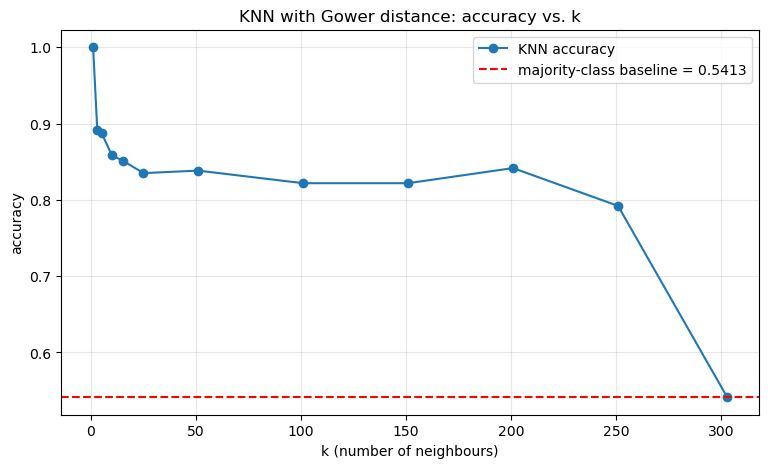

For k = n (every point is a neighbour of every other point) the model always predicts the
majority class, so the accuracy converges to the baseline of 0.5413.
For k = 1 the accuracy is 1.0 only because each point is its own nearest neighbour (distance 0).


,k,accuracy
0,1,1.0000
1,3,0.8911
2,5,0.8878
3,10,0.8581
4,15,0.8515
5,25,0.8350
6,51,0.8383
7,101,0.8218
8,151,0.8218
9,201,0.8416


In [13]:
ks, accs = [1, 3, 5, 10, 15, 25, 51, 101, 151, 201, 251, len(y)], []
for k in ks:
    accs.append(KNeighborsClassifier(n_neighbors=k, metric='precomputed')
                .fit(D_gower, y).score(D_gower, y))

baseline = max(y.mean(), 1 - y.mean())

plt.figure(figsize=(9, 5))
plt.plot(ks, accs, marker='o', label='KNN accuracy')
plt.axhline(baseline, color='red', linestyle='--',
            label=f'majority-class baseline = {baseline:.4f}')
plt.xlabel('k (number of neighbours)')
plt.ylabel('accuracy')
plt.title('KNN with Gower distance: accuracy vs. k')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("For k = n (every point is a neighbour of every other point) the model "
      "always predicts the\nmajority class, so the accuracy converges to the "
      f"baseline of {baseline:.4f}.")
print("For k = 1 the accuracy is 1.0 only because each point is its own "
      "nearest neighbour (distance 0).")

pd.DataFrame({'k': ks, 'accuracy': np.round(accs, 4)})

<h2 style="color:blue">Task 4 - Random Forest</h2>

Apply the Random Forest Method and calculate the accuracy.  
Which model is the best one?

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_enc, y)

acc_rf = rf.score(X_enc, y)
print(f"Random forest accuracy: {acc_rf:.4f}\n")

importances_rf = (pd.Series(rf.feature_importances_, index=X_enc.columns)
                    .sort_values(ascending=False))
print("Feature importances:")
print(importances_rf.round(4))

Random forest accuracy: 1.0000

Feature importances:
cp          0.1341
thalach     0.1288
ca          0.1168
oldpeak     0.1057
thal        0.0916
age         0.0893
chol        0.0769
trestbps    0.0763
exang       0.0636
slope       0.0530
sex         0.0329
restecg     0.0205
fbs         0.0103
dtype: float64


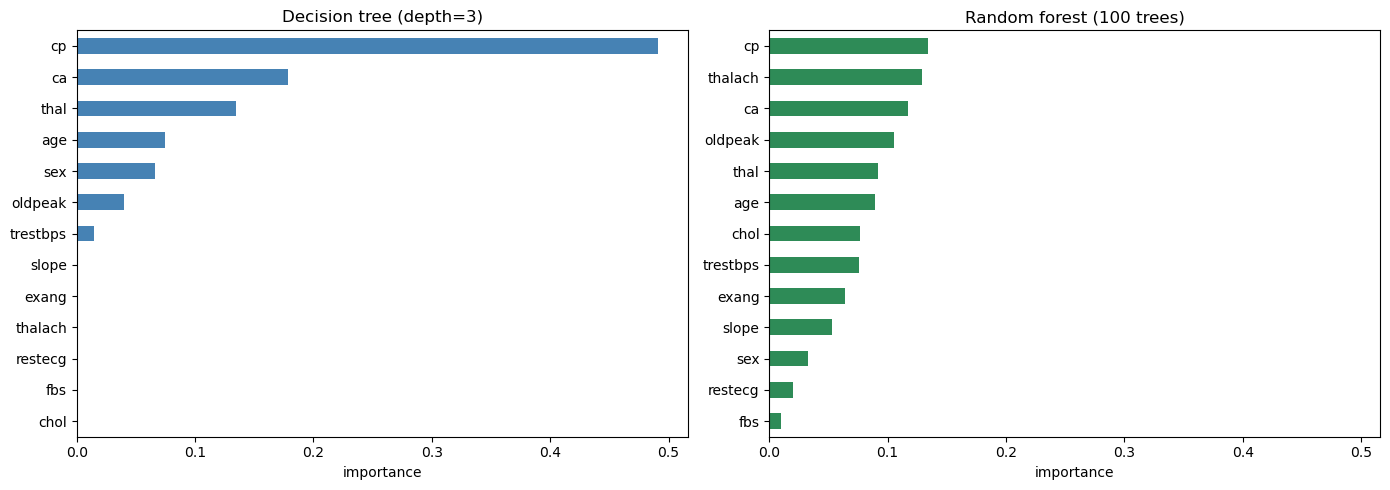

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

importances_dt.sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Decision tree (depth=3)')
axes[0].set_xlabel('importance')

importances_rf.sort_values().plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Random forest (100 trees)')
axes[1].set_xlabel('importance')

plt.tight_layout()
plt.show()

In [16]:
summary = (pd.DataFrame({
    'Model': ['Decision tree (depth=3)',
              'Logistic regression (integer encoded)',
              'Logistic regression (one-hot encoded)',
              'KNN (k=5, Gower)',
              'Random forest (100 trees)'],
    'Accuracy': [acc_dt, acc_lr_enc, acc_lr_ohe, acc_knn, acc_rf],
}).sort_values('Accuracy', ascending=False).reset_index(drop=True))

summary['Accuracy'] = summary['Accuracy'].round(4)
summary

,Model,Accuracy
0,Random forest (100 trees),1.0000
1,"KNN (k=5, Gower)",0.8878
2,Logistic regression (one-hot encoded),0.8713
3,Logistic regression (integer encoded),0.8515
4,Decision tree (depth=3),0.8449


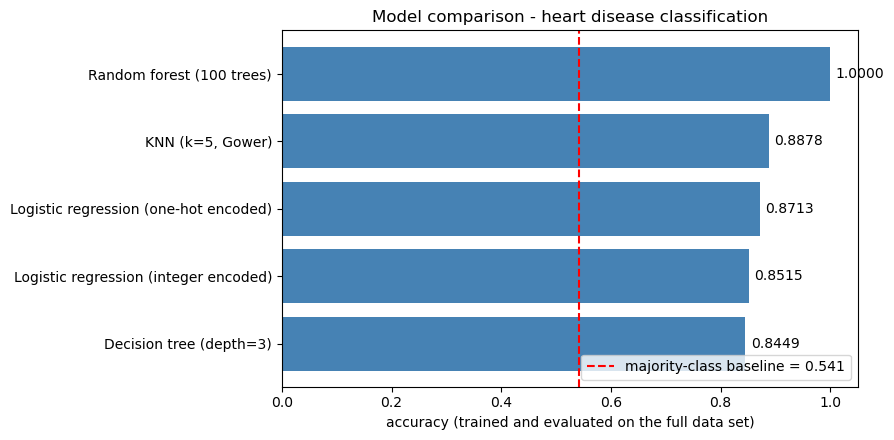

In [17]:
plt.figure(figsize=(9, 4.5))
bars = plt.barh(summary['Model'][::-1], summary['Accuracy'][::-1], color='steelblue')
plt.axvline(baseline, color='red', linestyle='--',
            label=f'majority-class baseline = {baseline:.3f}')
plt.xlim(0, 1.05)
plt.xlabel('accuracy (trained and evaluated on the full data set)')
plt.title('Model comparison - heart disease classification')

for bar, v in zip(bars, summary['Accuracy'][::-1]):
    plt.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f'{v:.4f}', va='center')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Which model is the best one?

Taken at face value the **random forest wins with a perfect accuracy of 1.0000** &mdash; but that number is meaningless here.

As the task prescribes, every model was **trained and evaluated on the same 303 patients**. A forest of 100 unpruned trees has more than enough capacity to simply memorise all of them, so a training accuracy of 1.0 is guaranteed by construction and says nothing about unseen patients. The same effect explains why KNN reaches 1.0 at $k=1$: with the point itself in the training set, its nearest neighbour is always itself at Gower distance 0.

Ranking the models by what can actually be defended:

* **Random forest &mdash; 1.0000.** Fully overfitted. Its true performance is unknown without held-out data.
* **KNN (k=5, Gower) &mdash; 0.8878.** Also optimistic, since every point is its own neighbour. For large $k$ the accuracy drops towards the majority-class baseline of 0.5413, because the model then simply predicts the most frequent class for everyone.
* **Logistic regression, one-hot encoded &mdash; 0.8713**, consistently better than the integer-encoded variant (**0.8515**). This is expected: integer encoding imposes an artificial order on unordered categories (e.g. `thal`: *fixed defect* < *normal* < *reversable defect*), and a linear model takes that ordering literally. One-hot encoding removes the false ordering, which is why it is the better choice despite the larger feature matrix (30 instead of 13 columns).
* **Decision tree (depth=3) &mdash; 0.8449.** The lowest score, but it is the only model that was *deliberately* restricted, so it is the least overfitted of the four and by far the easiest to interpret.

All models clearly beat the majority-class baseline of **0.5413**, so the features do carry real signal.

**Conclusion.** Under this protocol (train = test) the ranking is dominated by model capacity rather than model quality, so the comparison cannot be decided fairly &mdash; exactly the point the task announces for the next lesson, where a train/test split or cross-validation is introduced. Judged on trustworthiness, the depth-3 decision tree gives the most honest number; judged on potential, the random forest is the most promising candidate but has to be re-evaluated on held-out data before any claim can be made.

Reassuringly, the models agree on **which features matter**: `cp` (chest pain type), `ca` (number of major vessels coloured by flourosopy), `thal` and `thalach` (maximum heart rate achieved) dominate both the single tree and the forest.